In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
import math

In [2]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [3]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [4]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [5]:
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import *
from oh_suppression.fibre_modes import *

In [6]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [7]:
import astropy.units as u

from astropy.modeling.models import Sersic2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Sersic2D.html

In [8]:
field_r_max = 125e-6
n_grid = 1000

x_1d = np.linspace(
    -field_r_max,
    field_r_max,
    n_grid
)

y_1d = np.linspace(
    -field_r_max,
    field_r_max,
    n_grid
)

x, y = np.meshgrid(
    x_1d,
    y_1d
)

In [9]:
from joblib import Parallel, delayed
import numpy as np


def eta_psf_2d_decentre_quadrant(
        prepared_modes,
        x, y,
        x_1d, y_1d,
        lam0,
        F_eff,
        alpha,
        decentre_x_quadrant,
        decentre_y_quadrant,
        E_S=1.0,
        return_mode_maps=True,
        n_jobs=1,
        backend="threading",
        batch_size="auto"
):
    """
    Calculate point-source coupling efficiency over the
    positive PSF-decentre quadrant.

    The electric-field overlap integrals are always evaluated
    on the fixed x/y fibre-plane integration grid.

    Parameters
    ----------
    prepared_modes : list
        Prepared fibre modes for ONE core radius.

    decentre_x_quadrant, decentre_y_quadrant : 1D arrays
        Non-negative PSF-centre displacement coordinates [m].

        Expected range:
            0 <= dx <= a
            0 <= dy <= a

    Returns
    -------
    eta_total_quadrant : 2D ndarray
        Total coupling-efficiency map in the positive quadrant.

    mode_eta_quadrants : dict
        Individual coupling-efficiency maps with keys
        (l, m, angular).
    """

    decentre_x_quadrant = np.asarray(
        decentre_x_quadrant
    )

    decentre_y_quadrant = np.asarray(
        decentre_y_quadrant
    )

    # ---------------------------------------------------------
    # Sanity checks
    # ---------------------------------------------------------

    if (
        np.any(decentre_x_quadrant < 0)
        or np.any(decentre_y_quadrant < 0)
    ):
        raise ValueError(
            "Quadrant decentre coordinates must be non-negative."
        )

    if (
        not np.isclose(decentre_x_quadrant[0], 0.0)
        or not np.isclose(decentre_y_quadrant[0], 0.0)
    ):
        raise ValueError(
            "Quadrant decentre coordinates must begin at zero."
        )

    nx = len(decentre_x_quadrant)
    ny = len(decentre_y_quadrant)

    # ---------------------------------------------------------
    # Prepare mode-map storage
    # ---------------------------------------------------------

    if return_mode_maps:

        mode_keys = [
            (
                mode["l"],
                mode["m"],
                mode["angular"]
            )
            for mode in prepared_modes
        ]

    else:

        mode_keys = None

    # ---------------------------------------------------------
    # Calculate one horizontal row
    # ---------------------------------------------------------

    def calculate_row(dy):

        eta_row = np.zeros(nx)

        if return_mode_maps:

            mode_rows = {
                key: np.zeros(nx)
                for key in mode_keys
            }

        else:

            mode_rows = None

        for ix, dx in enumerate(
            decentre_x_quadrant
        ):

            eta_total, mode_results = total_eff_2d(
                prepared_modes=prepared_modes,
                x=x,
                y=y,
                x_1d=x_1d,
                y_1d=y_1d,
                lam0=lam0,
                F_eff=F_eff,
                alpha=alpha,
                decentre=(dx, dy),
                E_S=E_S
            )

            eta_row[ix] = eta_total

            if return_mode_maps:

                for result in mode_results:

                    key = (
                        result["l"],
                        result["m"],
                        result["angular"]
                    )

                    mode_rows[key][ix] = (
                        result["eta"]
                    )

        return eta_row, mode_rows

    # ---------------------------------------------------------
    # Calculate every y row
    # ---------------------------------------------------------

    if n_jobs == 1:

        row_results = []

        for iy, dy in enumerate(
            decentre_y_quadrant
        ):

            row_results.append(
                calculate_row(dy)
            )

            print(
                f"{iy + 1}/{ny} quadrant rows complete "
                f"({100 * (iy + 1) / ny:.1f}%)"
            )

    else:

        row_results = Parallel(
            n_jobs=n_jobs,
            backend="threading",
            batch_size="auto",
            verbose=10
        )(
            delayed(calculate_row)(dy)
            for dy in decentre_y_quadrant
        )

    # ---------------------------------------------------------
    # Assemble quadrant arrays
    # ---------------------------------------------------------

    eta_total_quadrant = np.array([
        result[0]
        for result in row_results
    ])

    if return_mode_maps:

        mode_eta_quadrants = {}

        for key in mode_keys:

            mode_eta_quadrants[key] = np.array([
                result[1][key]
                for result in row_results
            ])

    else:

        mode_eta_quadrants = None

    return (
        eta_total_quadrant,
        mode_eta_quadrants
    )

In [10]:
def mirror_quadrant_map(
        quadrant_map
):
    """
    Mirror a positive-quadrant efficiency map into the full
    x-y plane.

    The input quadrant includes x=0 and y=0.

    The zero row and zero column are NOT duplicated.

    If the quadrant is N x N, the returned full map is:
        (2N - 1) x (2N - 1)
    """

    # ---------------------------------------------------------
    # Mirror across y-axis
    #
    # Exclude column 0 before flipping so x=0 appears once.
    # ---------------------------------------------------------

    negative_x = np.flip(
        quadrant_map[:, 1:],
        axis=1
    )

    full_x = np.concatenate(
        (
            negative_x,
            quadrant_map
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # Mirror across x-axis
    #
    # Exclude row 0 before flipping so y=0 appears once.
    # ---------------------------------------------------------

    negative_y = np.flip(
        full_x[1:, :],
        axis=0
    )

    full_map = np.concatenate(
        (
            negative_y,
            full_x
        ),
        axis=0
    )

    return full_map

In [11]:
def psf_2d_decentre_map(
    a,
    x,
    y,
    x_1d,
    y_1d,
    lam0,
    NA,
    l_max=10,
    m_max=5,
    F_eff=None,
    alpha=0.0,
    n_decentre_quadrant=51,
    E_S=1.0,
    mode_case="few_mode",
    n_jobs=1,
    backend="threading",
    batch_size="auto",
    expected_LP_families=None,
    expected_prepared_components=None,
):
    """
    Calculate full 2D point-source coupling-efficiency maps
    for ONE fibre core radius.

    The overlap-integral grid is supplied separately through
    x, y, x_1d, y_1d.

    The PSF-centre displacement is restricted to:

        0 <= dx <= a
        0 <= dy <= a

    in the calculated quadrant.

    The efficiency maps are then mirrored into the full plane.
    """

    # ---------------------------------------------------------
    # Effective focal ratio
    # ---------------------------------------------------------

    if F_eff is None:

        F_eff = 1 / (
            2 * np.tan(
                np.arcsin(NA)
            )
        )

    # ---------------------------------------------------------
    # Prepare all supported fibre modes
    # ---------------------------------------------------------

    prepared_modes = prepare_modes_2d(
        x,
        y,
        a=a,
        NA=NA,
        lam0=lam0,
        az_sym=False,
        mode_case=mode_case, 
        l_max=l_max,
        m_max=m_max,
    )

    # ---------------------------------------------------------
    # PSF decentre range for THIS fibre radius
    # ---------------------------------------------------------

    decentre_max = a

    decentre_x_quadrant = np.linspace(
        0.0,
        decentre_max,
        n_decentre_quadrant
    )

    decentre_y_quadrant = np.linspace(
        0.0,
        decentre_max,
        n_decentre_quadrant
    )

    # ---------------------------------------------------------
    # Calculate positive quadrant
    # ---------------------------------------------------------

    (
        eta_total_quadrant,
        mode_eta_quadrants
    ) = eta_psf_2d_decentre_quadrant(
        prepared_modes=prepared_modes,
        x=x,
        y=y,
        x_1d=x_1d,
        y_1d=y_1d,
        lam0=lam0,
        F_eff=F_eff,
        alpha=alpha,
        decentre_x_quadrant=decentre_x_quadrant,
        decentre_y_quadrant=decentre_y_quadrant,
        E_S=E_S,
        return_mode_maps=True,
        n_jobs=n_jobs
    )

    # ---------------------------------------------------------
    # Mirror total map
    # ---------------------------------------------------------

    eta_total_map = mirror_quadrant_map(
        eta_total_quadrant
    )

    # ---------------------------------------------------------
    # Mirror each individual mode map
    # ---------------------------------------------------------

    mode_eta_maps = {}

    for key, quadrant_map in (
        mode_eta_quadrants.items()
    ):

        mode_eta_maps[key] = (
            mirror_quadrant_map(
                quadrant_map
            )
        )

    # ---------------------------------------------------------
    # Construct coordinates corresponding EXACTLY to the
    # returned full maps
    # ---------------------------------------------------------

    decentre_x_full = np.concatenate(
        (
            -decentre_x_quadrant[1:][::-1],
            decentre_x_quadrant
        )
    )

    decentre_y_full = np.concatenate(
        (
            -decentre_y_quadrant[1:][::-1],
            decentre_y_quadrant
        )
    )

    # ---------------------------------------------------------
    # Return everything needed downstream
    # ---------------------------------------------------------

    return {
        "a": a,
        "F_eff": F_eff,

        "decentre_x_1d":
            decentre_x_full,

        "decentre_y_1d":
            decentre_y_full,

        "eta_total_map":
            eta_total_map,

        "mode_eta_maps":
            mode_eta_maps
    }

In [12]:
import time

def eta_maps_vs_core_radius(
        core_radius_array,
        x, y,
        x_1d, y_1d,
        NA,
        lam0,
        alpha=0.0,
        F_eff=None,
        n_decentre_quadrant=51,
        mode_case="few_mode",
        E_S=1.0,
        n_jobs=1
):
    """
    Calculate full 2D PSF-decentre coupling maps for a range
    of fibre core radii.

    Fibre radii are processed serially.

    Parallel processing, if requested, occurs only over rows
    within each quadrant calculation.
    """

    core_radius_array = np.asarray(
        core_radius_array
    )

    if F_eff is None:

        F_eff = 1 / (
            2 * np.tan(
                np.arcsin(NA)
            )
        )

    results_all_radius = []

    n_total = len(
        core_radius_array
    )

    start_time = time.time()

    # ---------------------------------------------------------
    # Serial outer loop over fibre radius
    # ---------------------------------------------------------

    for i, a in enumerate(
        core_radius_array
    ):

        quadrant_spacing = (
            a
            /
            (n_decentre_quadrant - 1)
        )

        print(
            f"\nCore radius = "
            f"{a * 1e6:.2f} µm "
            f"({i + 1}/{n_total})"
        )

        print(
            f"PSF decentre quadrant: "
            f"0 to {a * 1e6:.2f} µm"
        )

        print(
            f"Decentre spacing = "
            f"{quadrant_spacing * 1e6:.3f} µm"
        )

        # -----------------------------------------------------
        # Calculate one radius
        # -----------------------------------------------------

        result = psf_2d_decentre_map(
            a=a,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            lam0=lam0,
            NA=NA,
            F_eff=F_eff,
            alpha=alpha,
            n_decentre_quadrant=
                n_decentre_quadrant,
            E_S=E_S,
            mode_case=mode_case,
            n_jobs=n_jobs
        )

        results_all_radius.append(
            result
        )

        # -----------------------------------------------------
        # Progress
        # -----------------------------------------------------

        elapsed = (
            time.time()
            -
            start_time
        )

        minutes = int(
            elapsed // 60
        )

        seconds = int(
            elapsed % 60
        )

        print(
            f"{100 * (i + 1) / n_total:.1f}% complete | "
            f"elapsed: "
            f"{minutes} min "
            f"{seconds:02d} sec"
        )

    return results_all_radius

In [13]:
core_radius_test = np.array([
    10e-6
])

results_test = eta_maps_vs_core_radius(
    core_radius_array=
        core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=0.1,
    lam0=1.5e-6,
    alpha=0.125,
    F_eff=None,
    n_decentre_quadrant=51,
    mode_case="few_mode",
    E_S=1.0,
    n_jobs=1
)


Core radius = 10.00 µm (1/1)
PSF decentre quadrant: 0 to 10.00 µm
Decentre spacing = 0.200 µm
1/51 quadrant rows complete (2.0%)
2/51 quadrant rows complete (3.9%)
3/51 quadrant rows complete (5.9%)
4/51 quadrant rows complete (7.8%)
5/51 quadrant rows complete (9.8%)
6/51 quadrant rows complete (11.8%)
7/51 quadrant rows complete (13.7%)
8/51 quadrant rows complete (15.7%)
9/51 quadrant rows complete (17.6%)
10/51 quadrant rows complete (19.6%)
11/51 quadrant rows complete (21.6%)
12/51 quadrant rows complete (23.5%)
13/51 quadrant rows complete (25.5%)
14/51 quadrant rows complete (27.5%)
15/51 quadrant rows complete (29.4%)
16/51 quadrant rows complete (31.4%)
17/51 quadrant rows complete (33.3%)
18/51 quadrant rows complete (35.3%)
19/51 quadrant rows complete (37.3%)
20/51 quadrant rows complete (39.2%)
21/51 quadrant rows complete (41.2%)
22/51 quadrant rows complete (43.1%)
23/51 quadrant rows complete (45.1%)
24/51 quadrant rows complete (47.1%)
25/51 quadrant rows complete (4

In [14]:
result = results_test[0]

print(
    result["eta_total_map"].shape
)

print(
    result["decentre_x_1d"].shape
)

print(
    result["decentre_x_1d"][0] * 1e6,
    result["decentre_x_1d"][-1] * 1e6
)

print(
    result["F_eff"]
)

(101, 101)
(101,)
-10.0 10.0
4.9749371855331


In [22]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selected_asymmetric_mode_family_maps(
        result,
        families,
        cmap="viridis",
        same_scale_per_row=True
):
    """
    Plot cosine, sine, and total coupling maps for selected
    asymmetric LP mode families.
    """

    mode_maps = result[
        "mode_eta_maps"
    ]

    decentre_x_1d = result[
        "decentre_x_1d"
    ]

    decentre_y_1d = result[
        "decentre_y_1d"
    ]

    nrows = len(families)

    fig = plt.figure(
        figsize=(15, 4.2 * nrows)
    )

    gs = fig.add_gridspec(
        nrows=nrows,
        ncols=4,
        width_ratios=[
            1,
            1,
            1,
            0.05
        ],
        wspace=0.25,
        hspace=0.35
    )

    extent = [
        decentre_x_1d.min() * 1e6,
        decentre_x_1d.max() * 1e6,
        decentre_y_1d.min() * 1e6,
        decentre_y_1d.max() * 1e6
    ]

    for i, (l, m) in enumerate(
        families
    ):

        eta_cos = mode_maps[
            (l, m, "cos")
        ]

        eta_sin = mode_maps[
            (l, m, "sin")
        ]

        eta_total = (
            eta_cos
            +
            eta_sin
        )

        maps = [
            eta_cos,
            eta_sin,
            eta_total
        ]

        titles = [
            rf"LP$_{{{l}{m}}}$ cosine",
            rf"LP$_{{{l}{m}}}$ sine",
            rf"LP$_{{{l}{m}}}$ total"
        ]

        if same_scale_per_row:

            vmin = 0.0

            vmax = max(
                np.max(eta_cos),
                np.max(eta_sin),
                np.max(eta_total)
            )

        else:

            vmin = None
            vmax = None

        for j in range(3):

            ax = fig.add_subplot(
                gs[i, j]
            )

            im = ax.imshow(
                maps[j],
                extent=extent,
                origin="lower",
                aspect="equal",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax
            )

            ax.set_title(
                titles[j]
            )

            ax.set_xlabel(
                r"$\Delta x$ ($\mu$m)"
            )

            ax.set_ylabel(
                r"$\Delta y$ ($\mu$m)"
            )

            ax.minorticks_on()

            # Fibre centre
            # ax.axhline(
            #     0,
            #     linewidth=0.5,
            #     alpha=0.4
            # )

            # ax.axvline(
            #     0,
            #     linewidth=0.5,
            #     alpha=0.4
            # )

        cax = fig.add_subplot(
            gs[i, 3]
        )

        cbar = fig.colorbar(
            im,
            cax=cax
        )

        cbar.set_label(
            r"Coupling efficiency, $\eta$"
        )

    plt.show()

In [24]:
# families = sorted({
#     (l, m)
#     for (
#         l,
#         m,
#         angular
#     ) in results_test[0][
#         "mode_eta_maps"
#     ].keys()
#     if l != 0
# })

# plot_selected_asymmetric_mode_family_maps(
#     result=results_test[0],
#     families=families
# )

In [17]:
core_radius_test = np.array([
    25e-6
])

results_test = eta_maps_vs_core_radius(
    core_radius_array=
        core_radius_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    NA=0.1,
    lam0=1.5e-6,
    alpha=0.125,
    F_eff=None,
    n_decentre_quadrant=51,
    mode_case="few_mode",
    E_S=1.0,
    n_jobs=4
)


Core radius = 25.00 µm (1/1)
PSF decentre quadrant: 0 to 25.00 µm
Decentre spacing = 0.500 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  2.0min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  4.0min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  5.0min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  7.3min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  9.0min


100.0% complete | elapsed: 10 min 44 sec


[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed: 10.6min finished


In [18]:
result = results_test[0]

print(
    result["eta_total_map"].shape
)

print(
    result["decentre_x_1d"].shape
)

print(
    result["decentre_x_1d"][0] * 1e6,
    result["decentre_x_1d"][-1] * 1e6
)

print(
    result["F_eff"]
)

(101, 101)
(101,)
-25.0 25.0
4.9749371855331


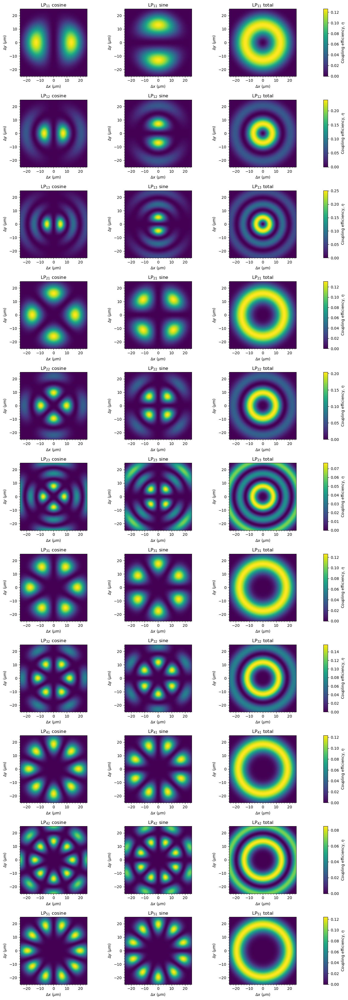

In [25]:
families = sorted({
    (l, m)
    for (
        l,
        m,
        angular
    ) in results_test[0][
        "mode_eta_maps"
    ].keys()
    if l != 0
})

plot_selected_asymmetric_mode_family_maps(
    result=results_test[0],
    families=families
)

In [20]:
import os
import psutil

process = psutil.Process(os.getpid())

ram_gb = process.memory_info().rss / 1024**3

print(f"Current notebook kernel RAM usage: {ram_gb:.2f} GB")

Current notebook kernel RAM usage: 0.28 GB


In [21]:
len(results_test[0]["mode_eta_maps"].keys())

26

In [13]:
import pandas as pd

def make_cutoff_table(
        l_max=6,
        m_max=5,
        V_max=None
):
    rows = []

    for l in range(l_max + 1):
        for m in range(1, m_max + 1):

            Vc = cutoff(l, m)

            if V_max is not None and Vc > V_max:
                continue

            rows.append({
                "l": l,
                "m": m,
                "Mode": f"LP{l}{m}",
                "V_cutoff": Vc,
                "n_components": 1 if l == 0 else 2
            })

    df = pd.DataFrame(rows)

    df = df.sort_values(
        ["V_cutoff", "l", "m"]
    ).reset_index(drop=True)

    return df

In [14]:
cutoff_table = make_cutoff_table(
    l_max=9,
    m_max=5,
    V_max=10
)

cutoff_table

,l,m,Mode,V_cutoff,n_components
0,0,1,LP01,0.000000,1
1,1,1,LP11,2.404826,2
2,0,2,LP02,3.831706,1
3,2,1,LP21,3.831706,2
4,3,1,LP31,5.135622,2
5,1,2,LP12,5.520078,2
6,4,1,LP41,6.380162,2
7,0,3,LP03,7.015587,1
8,2,2,LP22,7.015587,2
9,5,1,LP51,7.588342,2


In [15]:
def make_mode_count_table(
        l_max=15,
        m_max=15,
        V_max=13.2,
        decimals=4
):
    cutoff_table = make_cutoff_table(
        l_max=l_max,
        m_max=m_max,
        V_max=V_max
    ).copy()

    # Group modes that share the same cutoff frequency
    cutoff_table["Vc_group"] = (
        cutoff_table["V_cutoff"]
        .round(decimals)
    )

    unique_Vc = sorted(
        cutoff_table["Vc_group"].unique()
    )

    rows = []

    cumulative_families = 0
    cumulative_components = 0

    # ---------------------------------------------------------
    # Only go to len(unique_Vc) - 1
    #
    # This guarantees that every V_min has a real next
    # cutoff frequency to use as V_max.
    # ---------------------------------------------------------

    for i in range(len(unique_Vc) - 1):

        V_min = unique_Vc[i]
        V_max_next = unique_Vc[i + 1]

        group = cutoff_table[
            cutoff_table["Vc_group"] == V_min
        ]

        modes_added = list(
            group["Mode"]
        )

        families_added = len(group)

        components_added = int(
            group["n_components"].sum()
        )

        cumulative_families += (
            families_added
        )

        cumulative_components += (
            components_added
        )

        rows.append({
            "V_min": V_min,
            "V_max": V_max_next,

            "Modes_added":
                ", ".join(modes_added),

            "Families_added":
                families_added,

            "Components_added":
                components_added,

            "Total_LP_families":
                cumulative_families,

            "Total_prepared_components":
                cumulative_components
        })

    return pd.DataFrame(rows)

In [16]:
mode_count_table = make_mode_count_table(
    l_max=15,
    m_max=15,
    V_max=13.2
)

mode_count_table

,V_min,V_max,Modes_added,Families_added,Components_added,Total_LP_families,Total_prepared_components
0,0.0000,2.4048,LP01,1,1,1,1
1,2.4048,3.8317,LP11,1,2,2,3
2,3.8317,5.1356,"LP02, LP21",2,3,4,6
3,5.1356,5.5201,LP31,1,2,5,8
4,5.5201,6.3802,LP12,1,2,6,10
5,6.3802,7.0156,LP41,1,2,7,12
6,7.0156,7.5883,"LP03, LP22",2,3,9,15
7,7.5883,8.4172,LP51,1,2,10,17
8,8.4172,8.6537,LP32,1,2,11,19
9,8.6537,8.7715,LP13,1,2,12,21


In [17]:
core_radius_array = np.linspace(
    2.5e-6,
    30e-6,
    276
)
core_radius_array

array([2.50e-06, 2.60e-06, 2.70e-06, 2.80e-06, 2.90e-06, 3.00e-06,
       3.10e-06, 3.20e-06, 3.30e-06, 3.40e-06, 3.50e-06, 3.60e-06,
       3.70e-06, 3.80e-06, 3.90e-06, 4.00e-06, 4.10e-06, 4.20e-06,
       4.30e-06, 4.40e-06, 4.50e-06, 4.60e-06, 4.70e-06, 4.80e-06,
       4.90e-06, 5.00e-06, 5.10e-06, 5.20e-06, 5.30e-06, 5.40e-06,
       5.50e-06, 5.60e-06, 5.70e-06, 5.80e-06, 5.90e-06, 6.00e-06,
       6.10e-06, 6.20e-06, 6.30e-06, 6.40e-06, 6.50e-06, 6.60e-06,
       6.70e-06, 6.80e-06, 6.90e-06, 7.00e-06, 7.10e-06, 7.20e-06,
       7.30e-06, 7.40e-06, 7.50e-06, 7.60e-06, 7.70e-06, 7.80e-06,
       7.90e-06, 8.00e-06, 8.10e-06, 8.20e-06, 8.30e-06, 8.40e-06,
       8.50e-06, 8.60e-06, 8.70e-06, 8.80e-06, 8.90e-06, 9.00e-06,
       9.10e-06, 9.20e-06, 9.30e-06, 9.40e-06, 9.50e-06, 9.60e-06,
       9.70e-06, 9.80e-06, 9.90e-06, 1.00e-05, 1.01e-05, 1.02e-05,
       1.03e-05, 1.04e-05, 1.05e-05, 1.06e-05, 1.07e-05, 1.08e-05,
       1.09e-05, 1.10e-05, 1.11e-05, 1.12e-05, 1.13e-05, 1.14e

In [18]:
rows = []

for a in core_radius_array:

    V = (
        2 * np.pi
        * a
        * 0.1
        / 1.5e-6
    )

    supported = modes(
        V,
        l_max=6,
        m_max=5,
        az_sym_only=False
    )

    n_families = len(supported)

    n_components = sum(
        1 if l == 0 else 2
        for l, m, Vc in supported
    )

    rows.append({
        "a_um": a * 1e6,
        "V": V,
        "n_LP_families": n_families,
        "n_prepared_components": n_components
    })

radius_mode_table = pd.DataFrame(rows)

In [19]:
radius_mode_table[225:]

,a_um,V,n_LP_families,n_prepared_components
225,25.0,10.471976,16,28
226,25.1,10.513863,16,28
227,25.2,10.555751,16,28
228,25.3,10.597639,16,28
229,25.4,10.639527,16,28
230,25.5,10.681415,16,28
231,25.6,10.723303,16,28
232,25.7,10.765191,16,28
233,25.8,10.807079,16,28
234,25.9,10.848967,16,28


In [20]:
np.sum(radius_mode_table['n_prepared_components'])

np.int64(4062)

In [147]:
for i in range(1,20): 
    # count the number of radii that support n number of n_LP_families
    count = np.sum(radius_mode_table['n_LP_families'] == i)
    print(f"Number of radii that support {i} LP families: {count}")

Number of radii that support 1 LP families: 33
Number of radii that support 2 LP families: 34
Number of radii that support 3 LP families: 0
Number of radii that support 4 LP families: 31
Number of radii that support 5 LP families: 9
Number of radii that support 6 LP families: 21
Number of radii that support 7 LP families: 15
Number of radii that support 8 LP families: 0
Number of radii that support 9 LP families: 14
Number of radii that support 10 LP families: 19
Number of radii that support 11 LP families: 6
Number of radii that support 12 LP families: 3
Number of radii that support 13 LP families: 24
Number of radii that support 14 LP families: 9
Number of radii that support 15 LP families: 0
Number of radii that support 16 LP families: 22
Number of radii that support 17 LP families: 13
Number of radii that support 18 LP families: 4
Number of radii that support 19 LP families: 13


In [21]:
# Calculate V for every fibre core radius
V_array = (
    2 * np.pi
    * core_radius_array
    * 0.1
    / 1.5e-6
)


# Count how many radii fall inside each V interval
mode_count_table["n_radii"] = [
    np.sum(
        (V_array >= V_min)
        & (V_array < V_max)
    )
    for V_min, V_max in zip(
        mode_count_table["V_min"],
        mode_count_table["V_max"]
    )
]

mode_count_table

,V_min,V_max,Modes_added,Families_added,Components_added,Total_LP_families,Total_prepared_components,n_radii
0,0.0000,2.4048,LP01,1,1,1,1,33
1,2.4048,3.8317,LP11,1,2,2,3,34
2,3.8317,5.1356,"LP02, LP21",2,3,4,6,31
3,5.1356,5.5201,LP31,1,2,5,8,9
4,5.5201,6.3802,LP12,1,2,6,10,21
5,6.3802,7.0156,LP41,1,2,7,12,15
6,7.0156,7.5883,"LP03, LP22",2,3,9,15,14
7,7.5883,8.4172,LP51,1,2,10,17,19
8,8.4172,8.6537,LP32,1,2,11,19,6
9,8.6537,8.7715,LP13,1,2,12,21,3


In [155]:
import pandas as pd

# Assumption:
# one prepared mode component for one fibre radius
# takes approximately 10 MB
MB_per_component = 10.0

# Number of coupling-component maps stored per radius
mode_count_table["components_per_radius"] = (
    mode_count_table["Total_prepared_components"]
)

# Estimated storage for each V-bin/file
mode_count_table["estimated_MB"] = (
    mode_count_table["n_radii"]
    * mode_count_table["components_per_radius"]
    * MB_per_component
)

mode_count_table["estimated_GB"] = (
    mode_count_table["estimated_MB"] / 1000
)

# Optional file number
mode_count_table["file"] = range(
    len(mode_count_table)
)

# Produce a cleaner summary table
storage_table = mode_count_table[
    [
        "file",
        "V_min",
        "V_max",
        "Modes_added",
        "Total_prepared_components",
        "n_radii",
        "estimated_MB",
        "estimated_GB"
    ]
].copy()

storage_table

,file,V_min,V_max,Modes_added,Total_prepared_components,n_radii,estimated_MB,estimated_GB
0,0,0.0000,2.4048,LP01,1,33,330.0,0.33
1,1,2.4048,3.8317,LP11,3,34,1020.0,1.02
2,2,3.8317,5.1356,"LP02, LP21",6,31,1860.0,1.86
3,3,5.1356,5.5201,LP31,8,9,720.0,0.72
4,4,5.5201,6.3802,LP12,10,21,2100.0,2.10
5,5,6.3802,7.0156,LP41,12,15,1800.0,1.80
6,6,7.0156,7.5883,"LP03, LP22",15,14,2100.0,2.10
7,7,7.5883,8.4172,LP51,17,19,3230.0,3.23
8,8,8.4172,8.6537,LP32,19,6,1140.0,1.14
9,9,8.6537,8.7715,LP13,21,3,630.0,0.63


In [85]:
# stepsize=0.1
core_radius_array_short = np.arange(2.5e-6, 30e-6, 0.5e-6)
core_radius_array_short

array([2.50e-06, 3.00e-06, 3.50e-06, 4.00e-06, 4.50e-06, 5.00e-06,
       5.50e-06, 6.00e-06, 6.50e-06, 7.00e-06, 7.50e-06, 8.00e-06,
       8.50e-06, 9.00e-06, 9.50e-06, 1.00e-05, 1.05e-05, 1.10e-05,
       1.15e-05, 1.20e-05, 1.25e-05, 1.30e-05, 1.35e-05, 1.40e-05,
       1.45e-05, 1.50e-05, 1.55e-05, 1.60e-05, 1.65e-05, 1.70e-05,
       1.75e-05, 1.80e-05, 1.85e-05, 1.90e-05, 1.95e-05, 2.00e-05,
       2.05e-05, 2.10e-05, 2.15e-05, 2.20e-05, 2.25e-05, 2.30e-05,
       2.35e-05, 2.40e-05, 2.45e-05, 2.50e-05, 2.55e-05, 2.60e-05,
       2.65e-05, 2.70e-05, 2.75e-05, 2.80e-05, 2.85e-05, 2.90e-05,
       2.95e-05, 3.00e-05])

In [86]:
import numpy as np


# ---------------------------------------------------------
# Coarse test radius array
# ---------------------------------------------------------

core_radius_array_short = np.arange(
    2.5e-6,
    30e-6,
    0.5e-6
)

V_array_short = (
    2 * np.pi
    * core_radius_array_short
    * 0.1
    / 1.5e-6
)

In [87]:
def select_core_radius_bin(
        bin_id,
        core_radius_array,
        V_array,
        mode_count_table
):
    """
    Select fibre core radii whose V-number lies within
    one chosen cutoff-frequency bin.

    Parameters
    ----------
    bin_id : int
        Bin/file number from mode_count_table.

    core_radius_array : 1D array
        Fibre core radii [m].

    V_array : 1D array
        V-number corresponding to each fibre radius.

    mode_count_table : pandas DataFrame
        Must contain columns:
            file
            V_min
            V_max

    Returns
    -------
    selected_radii : 1D array
        Core radii belonging to the selected V-bin.

    selected_V : 1D array
        Corresponding V values.

    V_min, V_max : float
        Cutoff-frequency limits of the selected bin.
    """

    # Get selected row
    row = mode_count_table.loc[
        mode_count_table["file"] == bin_id
    ]

    if len(row) == 0:
        raise ValueError(
            f"Bin {bin_id} not found."
        )

    row = row.iloc[0]

    V_min = float(
        row["V_min"]
    )

    V_max = float(
        row["V_max"]
    )

    # Select values inside:
    # V_min <= V < V_max
    mask = (
        (V_array >= V_min)
        &
        (V_array < V_max)
    )

    selected_radii = (
        core_radius_array[mask]
    )

    selected_V = (
        V_array[mask]
    )

    print(
        f"Bin {bin_id}: "
        f"{V_min:.4f} <= V < {V_max:.4f}"
    )

    print(
        f"Number of radii = "
        f"{len(selected_radii)}"
    )

    if len(selected_radii) > 0:

        print(
            f"Radius range = "
            f"{selected_radii.min() * 1e6:.2f} "
            f"to "
            f"{selected_radii.max() * 1e6:.2f} µm"
        )

    return (
        selected_radii,
        selected_V,
        V_min,
        V_max
    )

In [88]:
(
    core_radius_bin_test,
    V_bin_test,
    V_min_test,
    V_max_test
) = select_core_radius_bin(
    bin_id=1,
    core_radius_array=
        core_radius_array_short,
    V_array=
        V_array_short,
    mode_count_table=
        mode_count_table
)

Bin 1: 2.4048 <= V < 3.8317
Number of radii = 7
Radius range = 6.00 to 9.00 µm


In [89]:
core_radius_bin_test * 1e6

array([6. , 6.5, 7. , 7.5, 8. , 8.5, 9. ])

In [90]:
V_bin_test

array([2.51327412, 2.72271363, 2.93215314, 3.14159265, 3.35103216,
       3.56047167, 3.76991118])

In [ ]:
# # import os
# # import time
# # import joblib
# # import numpy as np


# def compute_and_save_coupling_maps_for_V_bin(
#         bin_id,
#         mode_count_table,
#         core_radius_array,
#         x, y,
#         x_1d, y_1d,
#         NA,
#         lam0,
#         alpha=0.0,
#         F_eff=None,
#         n_decentre_quadrant=51,
#         mode_case="few_mode",
#         E_S=1.0,
#         n_jobs=1,
#         output_dir="coupling_results",
#         compress=0
# ):
#     """
#     Select one V-number bin, calculate 2D PSF-decentre
#     coupling maps for all fibre radii in that bin,
#     and save the result to one file.

#     The selected interval is:

#         V_min <= V < V_max

#     where V_min and V_max are taken from mode_count_table
#     using bin_id.

#     Parameters
#     ----------
#     bin_id : int
#         File/bin number from mode_count_table.

#     mode_count_table : pandas.DataFrame
#         Must contain:
#             file
#             V_min
#             V_max

#     core_radius_array : 1D array
#         Fibre core radii [m].

#         This can be either:
#             - coarse laptop test array
#             - full 276-radius production array

#     x, y : 2D arrays
#         Fixed overlap-integral grid.

#     x_1d, y_1d : 1D arrays
#         Coordinate axes of overlap-integral grid.

#     NA : float
#         Fibre numerical aperture.

#     lam0 : float
#         Wavelength [m].

#     alpha : float
#         Central obstruction ratio.

#     F_eff : float or None
#         Effective focal ratio.
#         If None, calculate from NA.

#     n_decentre_quadrant : int
#         Number of decentre samples from 0 to a
#         in each quadrant direction.

#     mode_case : str
#         Fibre mode case.

#     E_S : float
#         Source electric-field amplitude.

#     n_jobs : int
#         Number of workers used inside each radius calculation.

#     output_dir : str
#         Folder where the bin file is saved.

#     compress : int
#         joblib compression level.
#         0 = no compression.

#     Returns
#     -------
#     filepath : str
#         Path of saved file.

#     results_all_radius : list
#         Calculated results for this bin.
#     """

#     core_radius_array = np.asarray(
#         core_radius_array
#     )

#     # ---------------------------------------------------------
#     # Calculate V for the supplied radius array
#     # ---------------------------------------------------------

#     V_array = (
#         2 * np.pi
#         * core_radius_array
#         * NA
#         / lam0
#     )

#     # ---------------------------------------------------------
#     # Get selected V-bin
#     # ---------------------------------------------------------

#     row = mode_count_table.loc[
#         mode_count_table["file"] == bin_id
#     ]

#     if len(row) == 0:
#         raise ValueError(
#             f"bin_id={bin_id} not found in mode_count_table."
#         )

#     row = row.iloc[0]

#     V_min = float(
#         row["V_min"]
#     )

#     V_max = float(
#         row["V_max"]
#     )

#     # ---------------------------------------------------------
#     # Select only radii inside this bin
#     # ---------------------------------------------------------

#     mask = (
#         (V_array >= V_min)
#         &
#         (V_array < V_max)
#     )

#     selected_radii = (
#         core_radius_array[mask]
#     )

#     selected_V = (
#         V_array[mask]
#     )

#     n_total = len(
#         selected_radii
#     )

#     if n_total == 0:
#         print(
#             f"No radii found in bin {bin_id}: "
#             f"{V_min:.4f} <= V < {V_max:.4f}"
#         )

#         return None, []

#     # ---------------------------------------------------------
#     # Effective focal ratio
#     # ---------------------------------------------------------

#     if F_eff is None:

#         F_eff = 1 / (
#             2 * np.tan(
#                 np.arcsin(NA)
#             )
#         )

#     # ---------------------------------------------------------
#     # Print selected bin information
#     # ---------------------------------------------------------

#     print("=" * 70)

#     print(
#         f"Bin {bin_id}"
#     )

#     print(
#         f"V range: "
#         f"{V_min:.4f} <= V < {V_max:.4f}"
#     )

#     print(
#         f"Number of radii: {n_total}"
#     )

#     print(
#         f"Radius range: "
#         f"{selected_radii.min() * 1e6:.3f} "
#         f"to "
#         f"{selected_radii.max() * 1e6:.3f} µm"
#     )

#     print(
#         f"F_eff = {F_eff:.4f}"
#     )

#     print("=" * 70)

#     # ---------------------------------------------------------
#     # Compute all radii in the selected bin
#     # ---------------------------------------------------------

#     results_all_radius = []

#     start_time = time.time()

#     for i, (a, V) in enumerate(
#         zip(
#             selected_radii,
#             selected_V
#         )
#     ):

#         quadrant_spacing = (
#             a
#             /
#             (n_decentre_quadrant - 1)
#         )

#         print(
#             f"\nCore radius = "
#             f"{a * 1e6:.3f} µm "
#             f"({i + 1}/{n_total})"
#         )

#         print(
#             f"V = {V:.4f}"
#         )

#         print(
#             f"PSF decentre quadrant: "
#             f"0 to {a * 1e6:.3f} µm"
#         )

#         print(
#             f"Decentre spacing = "
#             f"{quadrant_spacing * 1e6:.3f} µm"
#         )

#         # -----------------------------------------------------
#         # Calculate one radius
#         # -----------------------------------------------------

#         result = psf_2d_decentre_map(
#             a=a,
#             x=x,
#             y=y,
#             x_1d=x_1d,
#             y_1d=y_1d,
#             lam0=lam0,
#             NA=NA,
#             F_eff=F_eff,
#             alpha=alpha,
#             n_decentre_quadrant=
#                 n_decentre_quadrant,
#             E_S=E_S,
#             mode_case=mode_case,
#             n_jobs=n_jobs
#         )

#         # Store the corresponding V explicitly
#         result["V"] = V

#         results_all_radius.append(
#             result
#         )

#         # -----------------------------------------------------
#         # Progress
#         # -----------------------------------------------------

#         elapsed = (
#             time.time()
#             -
#             start_time
#         )

#         minutes = int(
#             elapsed // 60
#         )

#         seconds = int(
#             elapsed % 60
#         )

#         print(
#             f"{100 * (i + 1) / n_total:.1f}% complete | "
#             f"elapsed: "
#             f"{minutes} min "
#             f"{seconds:02d} sec"
#         )

#     # ---------------------------------------------------------
#     # Package bin results
#     # ---------------------------------------------------------

#     output = {
#         "bin_id": bin_id,
#         "V_min": V_min,
#         "V_max": V_max,

#         "core_radius_array":
#             selected_radii,

#         "V_array":
#             selected_V,

#         "NA": NA,
#         "lam0": lam0,
#         "alpha": alpha,
#         "F_eff": F_eff,

#         "n_decentre_quadrant":
#             n_decentre_quadrant,

#         "mode_case":
#             mode_case,

#         "E_S":
#             E_S,

#         "results":
#             results_all_radius
#     }

#     # ---------------------------------------------------------
#     # Save one file for this bin
#     # ---------------------------------------------------------

#     os.makedirs(
#         output_dir,
#         exist_ok=True
#     )

#     filename = (
#         f"coupling_maps_"
#         f"bin_{bin_id:02d}_"
#         f"V_{V_min:.4f}_"
#         f"to_{V_max:.4f}.joblib"
#     )

#     filepath = os.path.join(
#         output_dir,
#         filename
#     )

#     joblib.dump(
#         output,
#         filepath,
#         compress=compress
#     )

#     print(
#         f"\nSaved bin {bin_id} to:"
#     )

#     print(
#         filepath
#     )

#     return (
#         filepath,
#         results_all_radius
#     )

In [140]:
def compute_and_save_coupling_maps_for_V_bin(
    bin_id,
    mode_count_table,
    core_radius_array,
    x,
    y,
    x_1d,
    y_1d,
    NA,
    lam0,
    l_max=10,
    m_max=5,
    alpha=0.0,
    F_eff=None,
    n_decentre_quadrant=None,
    mode_case="few_mode",
    E_S=1.0,
    n_jobs=1,
    backend="threading",
    batch_size="auto",
    output_dir="coupling_results",
    compress=0,
):
    """
    Calculate and save all 2D coupling maps for one V-number bin.

    Parameters
    ----------
    l_max : int, default=10
        Maximum azimuthal LP-mode order considered.

    m_max : int, default=5
        Maximum radial LP-mode order considered.

        The defaults l_max=10 and m_max=5 are intended for the
        current parameter range:
            a <= 30 microns
            NA = 0.1
            lam0 = 1.5 microns

        For larger NA, larger core radii, or shorter wavelength,
        increase these limits.

    Notes
    -----
    The expected number of LP families and prepared cos/sin
    components is taken from mode_count_table and checked against
    the modes actually prepared by prepare_modes_2d().

    If n_decentre_quadrant is None, the resolution is selected using
    choose_bin_decentre_resolution().

    Bin 0 is not calculated here because it uses the radially
    symmetric LP01 method.
    """

    core_radius_array = np.asarray(
        core_radius_array
    )

    # ---------------------------------------------------------
    # Bin 0 uses radial symmetry
    # ---------------------------------------------------------

    if bin_id == 0:
        print(
            "Bin 0 uses the radially symmetric LP01 method; "
            "no 2D maps calculated."
        )
        return None, []

    # ---------------------------------------------------------
    # Calculate V for supplied radii
    # ---------------------------------------------------------

    V_array = (
        2 * np.pi
        * core_radius_array
        * NA
        / lam0
    )

    # ---------------------------------------------------------
    # Get row corresponding to this mode-count bin
    # ---------------------------------------------------------

    row = mode_count_table.loc[
        mode_count_table["file"] == bin_id
    ]

    if len(row) == 0:
        raise ValueError(
            f"bin_id={bin_id} not found in mode_count_table."
        )

    row = row.iloc[0]

    # Expected mode numbers from the table
    expected_LP_families = int(
        row["Total_LP_families"]
    )

    expected_prepared_components = int(
        row["Total_prepared_components"]
    )

    # ---------------------------------------------------------
    # Select radii belonging to this bin
    # ---------------------------------------------------------

    (
        selected_radii,
        selected_V,
        V_min,
        V_max,
    ) = select_core_radius_bin(
        bin_id=bin_id,
        core_radius_array=core_radius_array,
        V_array=V_array,
        mode_count_table=mode_count_table,
    )

    n_total = len(
        selected_radii
    )

    if n_total == 0:

        print(
            f"No radii found in bin {bin_id}: "
            f"{V_min:.4f} <= V < {V_max:.4f}"
        )

        return None, []

    # ---------------------------------------------------------
    # Choose map resolution
    # ---------------------------------------------------------

    if n_decentre_quadrant is None:

        n_decentre_quadrant = (
            choose_bin_decentre_resolution(
                bin_id=bin_id,
                mode_count_table=mode_count_table,
                core_radius_array=core_radius_array,
                NA=NA,
                lam0=lam0,
                x_1d=x_1d,
                n_fixed=51,
            )
        )

    # ---------------------------------------------------------
    # Effective focal ratio
    # ---------------------------------------------------------

    if F_eff is None:

        F_eff = (
            1
            / (
                2
                * np.tan(
                    np.arcsin(NA)
                )
            )
        )

    # ---------------------------------------------------------
    # Print bin information
    # ---------------------------------------------------------

    print("=" * 70)

    print(
        f"Bin {bin_id}"
    )

    print(
        f"V range: "
        f"{V_min:.4f} <= V < {V_max:.4f}"
    )

    print(
        f"Number of radii: {n_total}"
    )

    print(
        f"Radius range: "
        f"{selected_radii.min() * 1e6:.3f} "
        f"to "
        f"{selected_radii.max() * 1e6:.3f} µm"
    )

    print(
        f"Mode search limits: "
        f"l_max={l_max}, "
        f"m_max={m_max}"
    )

    print(
        f"Expected LP families: "
        f"{expected_LP_families}"
    )

    print(
        f"Expected prepared components: "
        f"{expected_prepared_components}"
    )

    print(
        f"n_decentre_quadrant = "
        f"{n_decentre_quadrant}"
    )

    print(
        f"full map size = "
        f"{2 * n_decentre_quadrant - 1} x "
        f"{2 * n_decentre_quadrant - 1}"
    )

    print(
        f"F_eff = {F_eff:.4f}"
    )

    print("=" * 70)

    # ---------------------------------------------------------
    # Calculate every radius in the bin
    # ---------------------------------------------------------

    results_all_radius = []

    start_time = time.time()

    for i, (a, V) in enumerate(
        zip(
            selected_radii,
            selected_V
        )
    ):

        quadrant_spacing = (
            a
            / (
                n_decentre_quadrant - 1
            )
        )

        print(
            f"\nCore radius = "
            f"{a * 1e6:.3f} µm "
            f"({i + 1}/{n_total})"
        )

        print(
            f"V = {V:.4f}"
        )

        print(
            f"Decentre spacing = "
            f"{quadrant_spacing * 1e6:.3f} µm"
        )

        # -----------------------------------------------------
        # Calculate one radius
        # -----------------------------------------------------

        result = psf_2d_decentre_map(
            a=a,
            x=x,
            y=y,
            x_1d=x_1d,
            y_1d=y_1d,
            lam0=lam0,
            NA=NA,

            l_max=l_max,
            m_max=m_max,

            F_eff=F_eff,
            alpha=alpha,

            n_decentre_quadrant=
                n_decentre_quadrant,

            E_S=E_S,
            mode_case=mode_case,

            n_jobs=n_jobs,
            backend=backend,
            batch_size=batch_size,

            expected_LP_families=
                expected_LP_families,

            expected_prepared_components=
                expected_prepared_components,
        )

        results_all_radius.append(
            result
        )

        # -----------------------------------------------------
        # Progress
        # -----------------------------------------------------

        elapsed = (
            time.time()
            - start_time
        )

        minutes = int(
            elapsed // 60
        )

        seconds = int(
            elapsed % 60
        )

        print(
            f"{100 * (i + 1) / n_total:.1f}% complete | "
            f"elapsed: "
            f"{minutes} min "
            f"{seconds:02d} sec"
        )

    # ---------------------------------------------------------
    # Package results
    # ---------------------------------------------------------

    output = {
        "bin_id": bin_id,

        "V_min": V_min,
        "V_max": V_max,

        "core_radius_array":
            selected_radii,

        "V_array":
            selected_V,

        "NA": NA,
        "lam0": lam0,

        "l_max": l_max,
        "m_max": m_max,

        "expected_LP_families":
            expected_LP_families,

        "expected_prepared_components":
            expected_prepared_components,

        "alpha": alpha,
        "F_eff": F_eff,

        "n_decentre_quadrant":
            n_decentre_quadrant,

        "full_map_size":
            2 * n_decentre_quadrant - 1,

        "mode_case":
            mode_case,

        "E_S":
            E_S,

        "backend":
            backend,

        "batch_size":
            batch_size,

        "results":
            results_all_radius,
    }

    # ---------------------------------------------------------
    # Save
    # ---------------------------------------------------------

    os.makedirs(
        output_dir,
        exist_ok=True,
    )

    filename = (
        f"coupling_maps_"
        f"bin_{bin_id:02d}_"
        f"V_{V_min:.4f}_"
        f"to_{V_max:.4f}.joblib"
    )

    filepath = os.path.join(
        output_dir,
        filename,
    )

    joblib.dump(
        output,
        filepath,
        compress=compress,
    )

    print(
        f"\nSaved bin {bin_id} to:"
    )

    print(
        filepath
    )

    return (
        filepath,
        results_all_radius
    )


In [95]:
output_dir = "/Users/tliu/oh_suppression/result/test_chuck_coupling_maps_jupyterhub"

In [97]:
filepath_test, results_test = (
    compute_and_save_coupling_maps_for_V_bin(
        bin_id=1,
        mode_count_table=mode_count_table,
        core_radius_array=core_radius_array_short,
        x=x,
        y=y,
        x_1d=x_1d,
        y_1d=y_1d,
        NA=0.1,
        lam0=1.5e-6,
        alpha=0.125,
        F_eff=None,
        n_decentre_quadrant=51,
        mode_case="few_mode",
        E_S=1.0,
        n_jobs=4,
        output_dir="/Users/tliu/oh_suppression/result/test_chuck_coupling_maps_jupyterhub",
        compress=0
    )
)

Bin 1
V range: 2.4048 <= V < 3.8317
Number of radii: 7
Radius range: 6.000 to 9.000 µm
F_eff = 4.9749

Core radius = 6.000 µm (1/7)
V = 2.5133
PSF decentre quadrant: 0 to 6.000 µm
Decentre spacing = 0.120 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   21.1s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   29.6s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   42.3s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   48.5s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  1.5min finished


14.3% complete | elapsed: 1 min 32 sec

Core radius = 6.500 µm (2/7)
V = 2.7227
PSF decentre quadrant: 0 to 6.500 µm
Decentre spacing = 0.130 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   17.8s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   25.3s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   38.1s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   45.1s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.3min
[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  1.4min finished


28.6% complete | elapsed: 2 min 59 sec

Core radius = 7.000 µm (3/7)
V = 2.9322
PSF decentre quadrant: 0 to 7.000 µm
Decentre spacing = 0.140 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   11.6s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   17.5s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   29.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   35.7s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:   51.9s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  1.3min finished


... (6 outputs left out)

85.7% complete | elapsed: 8 min 58 sec

Core radius = 9.000 µm (7/7)
V = 3.7699
PSF decentre quadrant: 0 to 9.000 µm
Decentre spacing = 0.180 µm


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   15.8s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   23.8s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   39.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:   48.7s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.6min


100.0% complete | elapsed: 10 min 48 sec

Saved bin 1 to:
/Users/tliu/oh_suppression/result/test_chuck_coupling_maps_jupyterhub/coupling_maps_bin_01_V_2.4048_to_3.8317.joblib


[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  1.8min finished


In [100]:
def load_coupling_map_results(filepath):
    """
    Load a saved V-bin coupling-map file.
    """

    loaded = joblib.load(filepath)

    results = loaded["results"]

    print(
        f"Bin {loaded['bin_id']}: "
        f"{loaded['V_min']:.4f} <= V < "
        f"{loaded['V_max']:.4f}"
    )

    print(
        f"Number of radii = {len(results)}"
    )

    print("\nIncluded radii:")

    for i, result in enumerate(
        results,
        start=1
    ):

        print(
            f"{i}: "
            f"a = {result['a'] * 1e6:.3f} µm, "
            f"V = {result['V']:.4f}, "
            f"modes = {len(result['mode_eta_maps'])}"
        )

    return loaded, results

In [101]:
loaded_test, results_test_loaded = (
    load_coupling_map_results(
        filepath_test
    )
)

Bin 1: 2.4048 <= V < 3.8317
Number of radii = 7

Included radii:
1: a = 6.000 µm, V = 2.5133, modes = 3
2: a = 6.500 µm, V = 2.7227, modes = 3
3: a = 7.000 µm, V = 2.9322, modes = 3
4: a = 7.500 µm, V = 3.1416, modes = 3
5: a = 8.000 µm, V = 3.3510, modes = 3
6: a = 8.500 µm, V = 3.5605, modes = 3
7: a = 9.000 µm, V = 3.7699, modes = 3


In [106]:
results_test_loaded[0]["eta_total_map"].shape

(101, 101)

In [102]:
def plot_all_mode_maps_at_one_radius(
        result,
        cmap="viridis"
):
    """
    Plot all individual mode-component coupling maps
    for one fibre core radius.
    """

    mode_maps = result[
        "mode_eta_maps"
    ]

    decentre_x_1d = result[
        "decentre_x_1d"
    ]

    decentre_y_1d = result[
        "decentre_y_1d"
    ]

    a = result["a"]
    V = result["V"]

    mode_keys = list(
        mode_maps.keys()
    )

    n_modes = len(
        mode_keys
    )

    # ---------------------------------------------------------
    # Figure layout
    # ---------------------------------------------------------

    ncols = 3

    nrows = int(
        np.ceil(
            n_modes / ncols
        )
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            5 * ncols,
            4.5 * nrows
        ),
        squeeze=False
    )

    extent = [
        decentre_x_1d.min() * 1e6,
        decentre_x_1d.max() * 1e6,
        decentre_y_1d.min() * 1e6,
        decentre_y_1d.max() * 1e6
    ]

    # ---------------------------------------------------------
    # Plot modes
    # ---------------------------------------------------------

    for ax, key in zip(
        axes.flat,
        mode_keys
    ):

        l, m, angular = key

        eta_map = mode_maps[key]

        im = ax.imshow(
            eta_map,
            origin="lower",
            extent=extent,
            aspect="equal",
            cmap=cmap
        )

        if l == 0:

            title = (
                rf"LP$_{{{l}{m}}}$"
            )

        else:

            title = (
                rf"LP$_{{{l}{m}}}$ "
                f"{angular}"
            )

        ax.set_title(title)

        ax.set_xlabel(
            r"$\Delta x$ ($\mu$m)"
        )

        ax.set_ylabel(
            r"$\Delta y$ ($\mu$m)"
        )

        ax.minorticks_on()

        fig.colorbar(
            im,
            ax=ax,
            label=r"Coupling efficiency, $\eta$"
        )

    # Turn off unused axes
    for ax in axes.flat[n_modes:]:
        ax.axis("off")

    fig.suptitle(
        (
            f"Core radius = "
            f"{a * 1e6:.3f} µm"
            f", V = {V:.4f}"
        ),
        fontsize=16
    )

    plt.tight_layout()

    plt.show()

In [119]:
results_test_loaded[0]["eta_total_map"].shape

(101, 101)

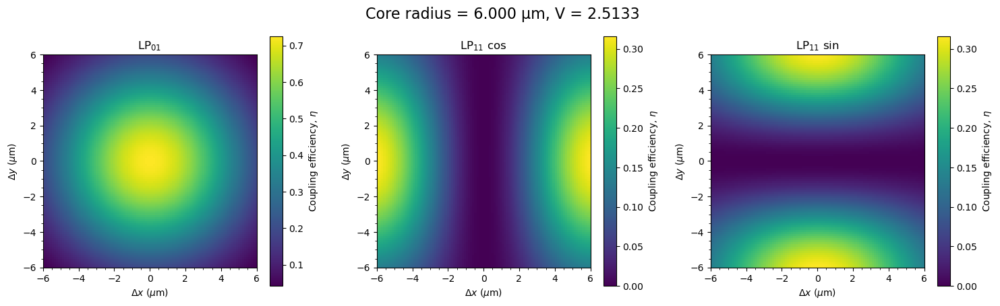

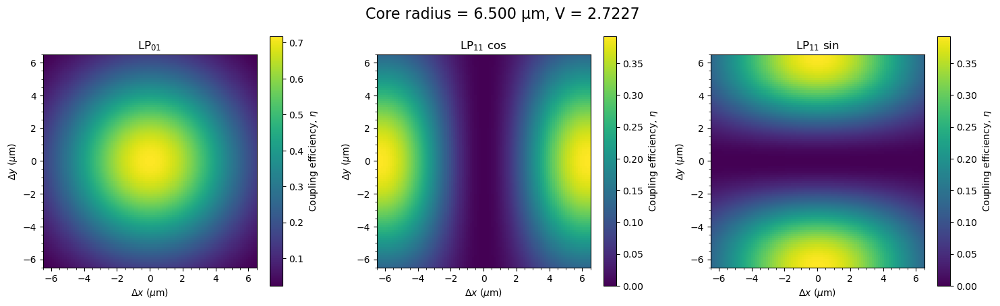

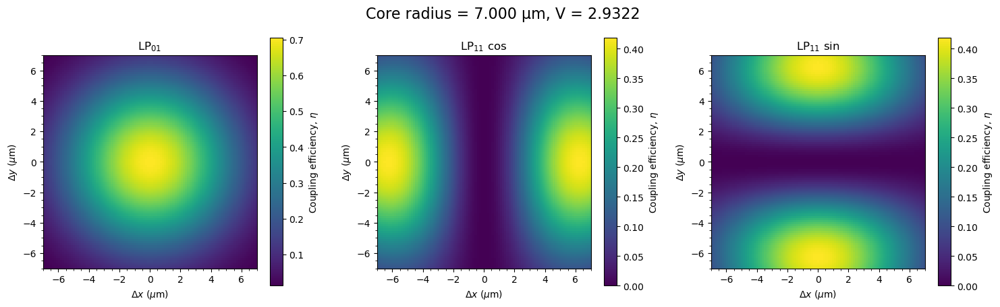

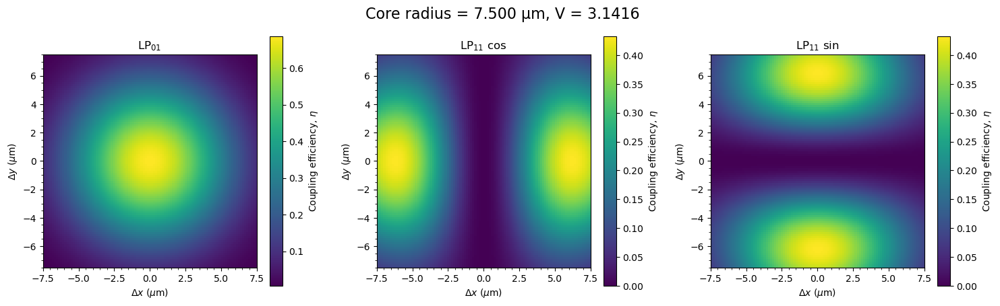

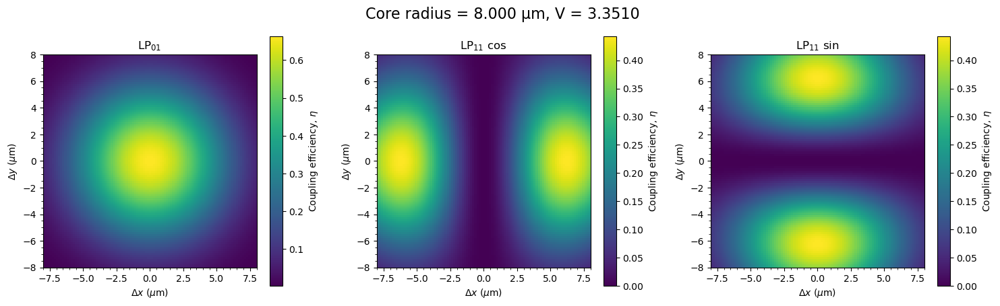

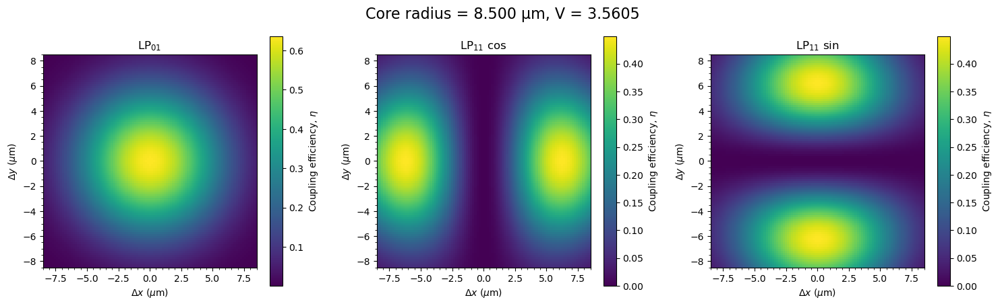

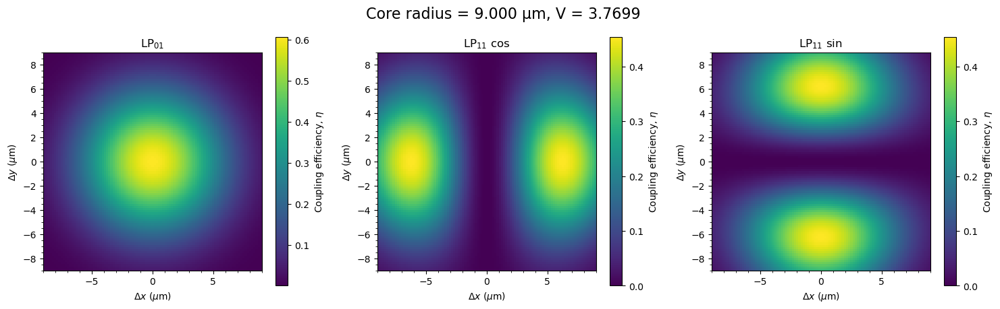

In [103]:
for result in results_test_loaded:

    plot_all_mode_maps_at_one_radius(
        result
    )

In [108]:
a_test = 30e-6

result_30um_51 = psf_2d_decentre_map(
    a=a_test,
    x=x,
    y=y,
    x_1d=x_1d,
    y_1d=y_1d,
    lam0=1.5e-6,
    NA=0.1,
    F_eff=None,
    alpha=0.125,
    n_decentre_quadrant=51,
    E_S=1.0,
    mode_case="few_mode",
    n_jobs=4
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  2.1min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  3.2min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  5.4min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  6.6min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed: 10.2min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed: 13.0min
[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed: 15.6min finished


In [112]:
import numpy as np
import matplotlib.pyplot as plt


def plot_all_coupling_maps(result, ncols=4, cmap="viridis"):
    """
    Plot total coupling efficiency and all individual
    mode coupling-efficiency maps for one fibre radius.
    """

    a = result["a"]
    V = result.get("V", 2 * np.pi * a * 0.1 / 1.5e-6)

    x_dec = result["decentre_x_1d"]
    y_dec = result["decentre_y_1d"]

    eta_total = result["eta_total_map"]
    mode_maps = result["mode_eta_maps"]

    # -----------------------------------------------------
    # Prepare list of maps
    # -----------------------------------------------------

    maps_to_plot = [
        ("Total", eta_total)
    ]

    for key, eta_map in mode_maps.items():

        l, m, angular = key

        if l == 0:
            label = rf"LP$_{{{l}{m}}}$"
        else:
            label = (
                rf"LP$_{{{l}{m}}}$ "
                f"{angular}"
            )

        maps_to_plot.append(
            (label, eta_map)
        )

    # -----------------------------------------------------
    # Figure layout
    # -----------------------------------------------------

    n_maps = len(maps_to_plot)

    nrows = int(
        np.ceil(
            n_maps / ncols
        )
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.5 * ncols, 4.2 * nrows),
        squeeze=False
    )

    extent = [
        x_dec.min() * 1e6,
        x_dec.max() * 1e6,
        y_dec.min() * 1e6,
        y_dec.max() * 1e6
    ]

    # -----------------------------------------------------
    # Plot maps
    # -----------------------------------------------------

    for ax, (title, eta_map) in zip(
        axes.flat,
        maps_to_plot
    ):

        im = ax.imshow(
            eta_map,
            origin="lower",
            extent=extent,
            aspect="equal",
            cmap=cmap
        )

        ax.set_title(
            title,
            fontsize=12
        )

        ax.set_xlabel(
            r"$\Delta x$ ($\mu$m)"
        )

        ax.set_ylabel(
            r"$\Delta y$ ($\mu$m)"
        )

        fig.colorbar(
            im,
            ax=ax,
            label=r"Coupling efficiency, $\eta$"
        )

    # Hide unused panels
    for ax in axes.flat[n_maps:]:
        ax.axis("off")

    fig.suptitle(
        rf"Core radius = {a * 1e6:.1f} $\mu$m, "
        rf"$V={V:.3f}$",
        fontsize=16,
        y=1.0
    )

    plt.tight_layout()

    plt.show()

In [130]:
# print all existin mode in result_30um_51
for key in result_30um_51["mode_eta_maps"].keys():
    l, m, angular = key
    if l == 0:
        label = rf"LP$_{{{l}{m}}}$"
    else:
        label = (
            rf"LP$_{{{l}{m}}}$ "
            f"{angular}"
        )
    print(label)

LP$_{01}$
LP$_{11}$ cos
LP$_{11}$ sin
LP$_{02}$
LP$_{21}$ cos
LP$_{21}$ sin
LP$_{31}$ cos
LP$_{31}$ sin
LP$_{12}$ cos
LP$_{12}$ sin
LP$_{41}$ cos
LP$_{41}$ sin
LP$_{03}$
LP$_{22}$ cos
LP$_{22}$ sin
LP$_{51}$ cos
LP$_{51}$ sin
LP$_{32}$ cos
LP$_{32}$ sin
LP$_{13}$ cos
LP$_{13}$ sin
LP$_{42}$ cos
LP$_{42}$ sin
LP$_{04}$
LP$_{23}$ cos
LP$_{23}$ sin
LP$_{52}$ cos
LP$_{52}$ sin
LP$_{33}$ cos
LP$_{33}$ sin
LP$_{14}$ cos
LP$_{14}$ sin


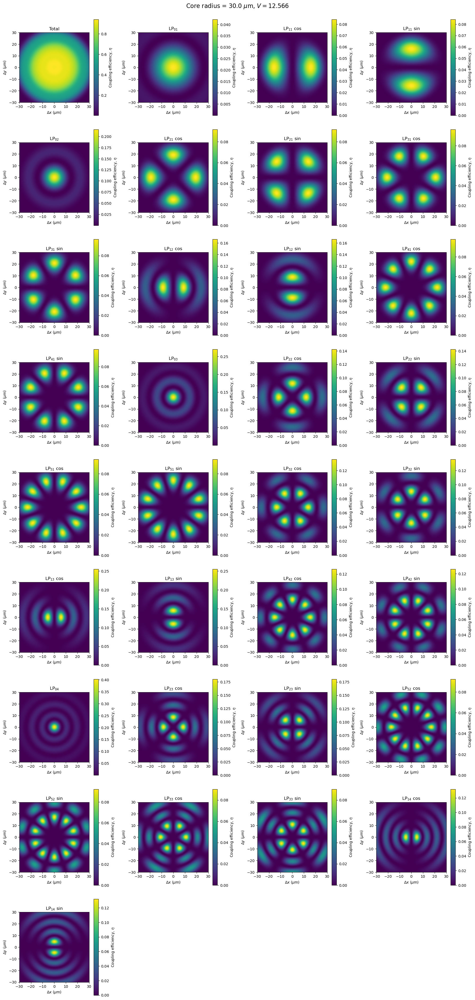

In [113]:
plot_all_coupling_maps(
    result_30um_51
)

In [115]:
NA=0.1
lam0=1.5e-6

In [116]:
import numpy as np
import time

bin_id = 4

# Get bin limits
row = mode_count_table.loc[
    mode_count_table["file"] == bin_id
].iloc[0]

V_min = row["V_min"]
V_max = row["V_max"]

# Calculate V for the full 276-radius array
V_array = (
    2 * np.pi
    * core_radius_array
    * NA
    / lam0
)

# Radii actually belonging to bin 4
mask = (
    (V_array >= V_min)
    & (V_array < V_max)
)

bin4_radii = core_radius_array[mask]

print(
    f"Number of radii = {len(bin4_radii)}"
)

print(
    f"Radius range = "
    f"{bin4_radii.min() * 1e6:.2f} - "
    f"{bin4_radii.max() * 1e6:.2f} µm"
)

# Original 1000 × 1000 field-grid spacing
field_spacing = np.abs(
    x_1d[1] - x_1d[0]
)

# Use largest radius in the bin
a_max = bin4_radii.max()

n_decentre_bin4 = (
    int(
        np.ceil(
            a_max / field_spacing
        )
    )
    + 1
)

print(
    f"n_decentre_quadrant = "
    f"{n_decentre_bin4}"
)

print(
    f"Full map = "
    f"{2 * n_decentre_bin4 - 1} × "
    f"{2 * n_decentre_bin4 - 1}"
)

Number of radii = 21
Radius range = 13.20 - 15.20 µm
n_decentre_quadrant = 62
Full map = 123 × 123


In [ ]:
def choose_bin_decentre_resolution(
        bin_id,
        mode_count_table,
        core_radius_array,
        NA,
        lam0,
        x_1d,
        n_fixed=51
):
    """
    Choose one decentre-quadrant resolution for a whole V-bin.

    Bin 0:
        Return None because LP01 can use the
        radially symmetric method.

    Bins 1-2:
        Use a fixed 51 x 51 positive quadrant,
        producing a 101 x 101 full map.

    Bin 3 onward:
        Choose the full-map resolution so that its physical
        pixel spacing is no coarser than the original 2D
        field-grid spacing.

        The full map is always forced to have an odd number
        of pixels so that (0, 0) is exactly the central pixel.
    """

    # ---------------------------------------------------------
    # Bin 0: radial method
    # ---------------------------------------------------------

    if bin_id == 0:
        return None

    # ---------------------------------------------------------
    # Bins 1-2: fixed moderate resolution
    # ---------------------------------------------------------

    if bin_id in [1, 2]:
        return n_fixed

    # ---------------------------------------------------------
    # Find radii belonging to this V-bin
    # ---------------------------------------------------------

    V_array = (
        2 * np.pi
        * core_radius_array
        * NA
        / lam0
    )

    row = mode_count_table.loc[
        mode_count_table["file"] == bin_id
    ].iloc[0]

    V_min = row["V_min"]
    V_max = row["V_max"]

    mask = (
        (V_array >= V_min)
        & (V_array < V_max)
    )

    selected_radii = core_radius_array[mask]

    if len(selected_radii) == 0:
        return None

    # Largest radius actually calculated in this bin
    a_max = selected_radii.max()

    # ---------------------------------------------------------
    # Original electric-field grid spacing
    # ---------------------------------------------------------

    field_spacing = np.abs(
        x_1d[1] - x_1d[0]
    )

    # ---------------------------------------------------------
    # Required FULL map size
    #
    # Full map runs from -a_max to +a_max,
    # so physical width = 2*a_max.
    # ---------------------------------------------------------

    n_full = (
        int(
            np.ceil(
                2 * a_max / field_spacing
            )
        )
        + 1
    )

    # Full map must be odd so that zero is a sampled
    # central pixel.
    if n_full % 2 == 0:
        n_full += 1

    # ---------------------------------------------------------
    # Convert full map size back to quadrant size
    #
    # n_full = 2*n_quadrant - 1
    # ---------------------------------------------------------

    n_quadrant = (
        n_full + 1
    ) // 2

    return n_quadrant

In [122]:
for bin_id in range(len(mode_count_table)):

    n_dec = choose_bin_decentre_resolution(
        bin_id=bin_id,
        mode_count_table=mode_count_table,
        core_radius_array=core_radius_array,
        NA=NA,
        lam0=lam0,
        x_1d=x_1d,
        n_fixed=51
    )

    if n_dec is None:
        print(
            f"Bin {bin_id:2d}: radial method / no 2D map"
        )

    else:
        n_full = 2 * n_dec - 1

        print(
            f"Bin {bin_id:2d}: "
            f"n_quadrant = {n_dec:3d}, "
            f"full map = {n_full:3d} x {n_full:3d}"
        )

Bin  0: radial method / no 2D map
Bin  1: n_quadrant =  51, full map = 101 x 101
Bin  2: n_quadrant =  51, full map = 101 x 101
Bin  3: n_quadrant =  54, full map = 107 x 107
Bin  4: n_quadrant =  62, full map = 123 x 123
Bin  5: n_quadrant =  68, full map = 135 x 135
Bin  6: n_quadrant =  74, full map = 147 x 147
Bin  7: n_quadrant =  81, full map = 161 x 161
Bin  8: n_quadrant =  84, full map = 167 x 167
Bin  9: n_quadrant =  85, full map = 169 x 169
Bin 10: n_quadrant =  95, full map = 189 x 189
Bin 11: n_quadrant =  98, full map = 195 x 195
Bin 12: n_quadrant = 107, full map = 213 x 213
Bin 13: n_quadrant = 112, full map = 223 x 223
Bin 14: n_quadrant = 114, full map = 227 x 227
Bin 15: n_quadrant = 119, full map = 237 x 237
Bin 16: n_quadrant = 121, full map = 241 x 241
Bin 17: radial method / no 2D map


In [170]:
import importlib
import oh_suppression.point_source_coupling as psc
import inspect

importlib.reload(psc)

<module 'oh_suppression.point_source_coupling' from '/Users/tliu/oh_suppression/codes/src/oh_suppression/point_source_coupling.py'>

In [171]:
prepare_modes_2d = psc.prepare_modes_2d
print(inspect.signature(prepare_modes_2d))
print(inspect.getsource(prepare_modes_2d))

(x, y, a, NA, lam0, az_sym=True, mode_case='few_mode', l_max=10, m_max=5)
def prepare_modes_2d(
    x, y,
    a, NA, lam0,
    az_sym=True,
    mode_case="few_mode",
    l_max=10, m_max=5
):
    """
    Prepare fibre mode fields for a fixed core radius.

    Parameters:
    x, y: 2D coordinate arrays at the fibre input plane [m]
    a: Core radius of the fibre [m]
    NA: Numerical aperture of the fibre
    lam0: Wavelength [m]
    l_max: Maximum value of the orbital angular momentum quantum number
    m_max: Maximum value of the azimuthal angular momentum quantum number
    az_sym: If True, only include azimuthally symmetric modes (l=0). If False, 
    include all modes up to l_max.
    mode_case:
        "smf"      -> only LP01
        "few_mode" -> all supported modes, optionally restricted by az_sym
    
    Returns value: 
    prepared_modes: A list of dictionaries containing precomputed fibre mode fields and their properties.
    Includes l, m, cutoff_V, X_root, Y_root, angular, 

In [172]:
core_radius_array_30microns = np.array([30e-6])

In [ ]:
filepath_test, results_test = (
    compute_and_save_coupling_maps_for_V_bin(
        bin_id=19,
        mode_count_table=mode_count_table,
        core_radius_array=core_radius_array_30microns,
        x=x,
        y=y,
        x_1d=x_1d,
        y_1d=y_1d,
        NA=0.1,
        lam0=1.5e-6,
        alpha=0.125,
        F_eff=None,
        n_decentre_quadrant=51,
        mode_case="few_mode",
        E_S=1.0,
        n_jobs=4,
        output_dir="/Users/tliu/oh_suppression/result/check_complete_30micron_radius",
        compress=0
    )
)

Bin 19: 12.3386 <= V < 13.0152
Number of radii = 1
Radius range = 30.00 to 30.00 µm
Bin 19
V range: 12.3386 <= V < 13.0152
Number of radii: 1
Radius range: 30.000 to 30.000 µm
Mode search limits: l_max=10, m_max=5
Expected LP families: 23
Expected prepared components: 42
n_decentre_quadrant = 51
full map size = 101 x 101
F_eff = 4.9749

Core radius = 30.000 µm (1/1)
V = 12.5664
Decentre spacing = 0.600 µm


[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  1.1min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  3.1min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  3.8min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  6.3min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  8.0min


100.0% complete | elapsed: 9 min 42 sec

Saved bin 19 to:
/Users/tliu/oh_suppression/result/check_complete_30micron_radius/coupling_maps_bin_19_V_12.3386_to_13.0152.joblib


[Parallel(n_jobs=4)]: Done  51 out of  51 | elapsed:  9.5min finished


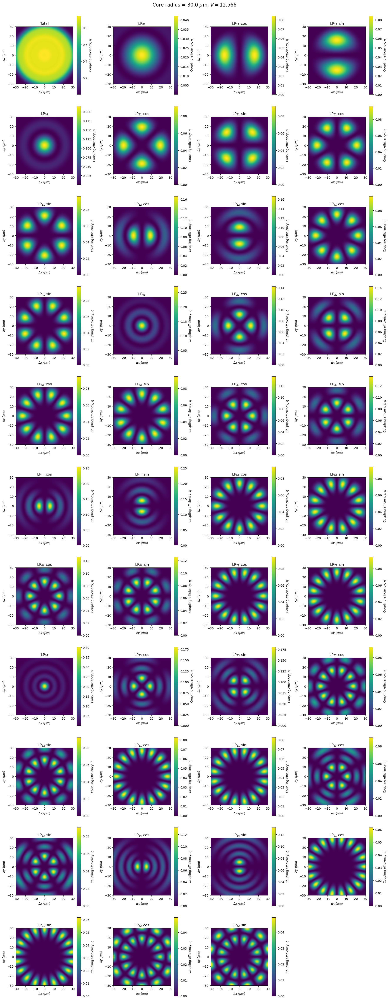

In [174]:
plot_all_coupling_maps(results_test[0])

In [175]:
for key in results_test[0]["mode_eta_maps"].keys():

    l, m, angular = key

    if l == 0:
        label = rf"LP$_{{{l}{m}}}$"
    else:
        label = (
            rf"LP$_{{{l}{m}}}$ "
            f"{angular}"
        )

    print(label)

LP$_{01}$
LP$_{11}$ cos
LP$_{11}$ sin
LP$_{02}$
LP$_{21}$ cos
LP$_{21}$ sin
LP$_{31}$ cos
LP$_{31}$ sin
LP$_{12}$ cos
LP$_{12}$ sin
LP$_{41}$ cos
LP$_{41}$ sin
LP$_{03}$
LP$_{22}$ cos
LP$_{22}$ sin
LP$_{51}$ cos
LP$_{51}$ sin
LP$_{32}$ cos
LP$_{32}$ sin
LP$_{13}$ cos
LP$_{13}$ sin
LP$_{61}$ cos
LP$_{61}$ sin
LP$_{42}$ cos
LP$_{42}$ sin
LP$_{71}$ cos
LP$_{71}$ sin
LP$_{04}$
LP$_{23}$ cos
LP$_{23}$ sin
LP$_{52}$ cos
LP$_{52}$ sin
LP$_{81}$ cos
LP$_{81}$ sin
LP$_{33}$ cos
LP$_{33}$ sin
LP$_{14}$ cos
LP$_{14}$ sin
LP$_{91}$ cos
LP$_{91}$ sin
LP$_{62}$ cos
LP$_{62}$ sin


In [182]:
def make_mode_count_table(
    l_max=10,
    m_max=5,
    V_limit=12.6,
    decimals=4,
):
    """
    Construct V-number bins for coupling-map calculations.

    The final bin extends to the first real LP-mode cutoff
    frequency greater than V_limit.
    """

    # ---------------------------------------------------------
    # Build a cutoff table extending beyond V_limit
    # ---------------------------------------------------------

    # Use a safety margin so that at least one cutoff above
    # V_limit is included.
    cutoff_table = make_cutoff_table(
        l_max=l_max,
        m_max=m_max,
        V_max=V_limit + 5.0,
    ).copy()

    # ---------------------------------------------------------
    # Group modes sharing the same cutoff
    # ---------------------------------------------------------

    cutoff_table["Vc_group"] = (
        cutoff_table["V_cutoff"]
        .round(decimals)
    )

    unique_Vc = np.sort(
        cutoff_table["Vc_group"].unique()
    )

    # ---------------------------------------------------------
    # Find first cutoff strictly above V_limit
    # ---------------------------------------------------------

    above_limit = unique_Vc[
        unique_Vc > V_limit
    ]

    if len(above_limit) == 0:
        raise ValueError(
            "No cutoff frequency found above V_limit. "
            "Increase the V range used to generate the cutoff table."
        )

    final_V_max = above_limit[0]

    rows = []

    cumulative_families = 0
    cumulative_components = 0

    # ---------------------------------------------------------
    # Construct bins
    # ---------------------------------------------------------

    for i in range(len(unique_Vc) - 1):

        V_min = unique_Vc[i]
        V_max_bin = unique_Vc[i + 1]

        # Stop once we have reached the first cutoff above V_limit
        if V_min >= final_V_max:
            break

        group = cutoff_table[
            cutoff_table["Vc_group"] == V_min
        ]

        modes_added = list(
            group["Mode"]
        )

        families_added = len(
            group
        )

        components_added = int(
            group["n_components"].sum()
        )

        cumulative_families += (
            families_added
        )

        cumulative_components += (
            components_added
        )

        rows.append({
            "V_min":
                float(V_min),

            "V_max":
                float(V_max_bin),

            "Modes_added":
                ", ".join(modes_added),

            "Families_added":
                families_added,

            "Components_added":
                components_added,

            "Total_LP_families":
                cumulative_families,

            "Total_prepared_components":
                cumulative_components,
        })

        # This is the final required bin
        if V_max_bin >= final_V_max:
            break

    # ---------------------------------------------------------
    # Convert to DataFrame
    # ---------------------------------------------------------

    mode_count_table = pd.DataFrame(
        rows
    )

    mode_count_table.insert(
        0,
        "file",
        np.arange(
            len(mode_count_table)
        )
    )

    return mode_count_table

In [183]:
make_mode_count_table()

,file,V_min,V_max,Modes_added,Families_added,Components_added,Total_LP_families,Total_prepared_components
0,0,0.0000,2.4048,LP01,1,1,1,1
1,1,2.4048,3.8317,LP11,1,2,2,3
2,2,3.8317,5.1356,"LP02, LP21",2,3,4,6
3,3,5.1356,5.5201,LP31,1,2,5,8
4,4,5.5201,6.3802,LP12,1,2,6,10
5,5,6.3802,7.0156,LP41,1,2,7,12
6,6,7.0156,7.5883,"LP03, LP22",2,3,9,15
7,7,7.5883,8.4172,LP51,1,2,10,17
8,8,8.4172,8.6537,LP32,1,2,11,19
9,9,8.6537,8.7715,LP13,1,2,12,21
